In [3]:
# QCNN with feature_map_circuit encoder + TCI surrogate
# This notebook builds a small QCNN in Yao, trains on a binary Fashion-MNIST subset,
# then fits a Tensor Cross Interpolation surrogate of the trained model.
using Pkg
Pkg.activate(".")
# Pkg.instantiate()  # uncomment on first run
include("Modules.jl")


  Activating project at `.`


Main.VQMLOracle

In [4]:
using Yao, Yao.ConstGate, LinearAlgebra, Statistics, Random
using Flux, MLDatasets
using TensorCrossInterpolation
using .FunctionTCI, .ForrelationFeature


In [5]:
import TensorCrossInterpolation as TCI
using LinearAlgebra, Random
using Statistics
using Plots

# ---------- 2-norm (Frobenius) relative error on the grid ----------
"""
relerr_grid_2norm(f_idx, dims, cores_F; nsamples=10_000, seed=0, exact_limit=100_000)

Returns ‖F - F̂‖₂ / ‖F‖₂ where F is the dense tensor of f_idx over the full grid
and F̂ is dense_from_tt(cores_F).

- Exact if prod(dims) ≤ exact_limit (default 100_000).
- Otherwise uses Monte-Carlo with nsamples uniformly random grid points.
"""

# ---- safer product to avoid overflow ----
function _prod_cap(dims::AbstractVector{<:Int}, cap::Int)
    total = 1
    for d in dims
        # if multiplying would exceed cap, return cap+1
        if total > cap ÷ d
            return cap + 1
        end
        total *= d
    end
    return total
end

"""
relerr_grid_2norm(f_idx, dims, cores_F; nsamples=10_000, seed=0, exact_limit=100_000)

Returns ‖F - F̂‖₂ / ‖F‖₂ where F is the dense tensor of f_idx over the full grid
and F̂ is dense_from_tt(cores_F).

- Exact if prod(dims) ≤ exact_limit (default 100_000).
- Otherwise uses Monte-Carlo with nsamples uniformly random grid points.
"""
function relerr_grid_2norm(f_idx, dims::AbstractVector{<:Int}, cores_F;
                           nsamples::Int=10_000, seed::Int=0, exact_limit::Int=100000)
    total = _prod_cap(dims, exact_limit)
    if total <= exact_limit
        # exact
        F  = zeros(Float64, dims...)
        It = Iterators.product((1:d for d in dims)...)
        for I in It
            F[I...] = f_idx(collect(I))
        end
        Fhat = dense_from_tt(cores_F)
        num = norm(F .- Fhat)
        den = max(norm(F), eps())
        return num/den
    else
        # MC estimate of Frobenius error
        rng = MersenneTwister(seed)

        sample_idx() = [rand(rng, 1:d) for d in dims]

        function ttF_eval(cores_F, I::Vector{Int})
            v = vec(@view cores_F[1][1, I[1], :])
            for p in 2:length(cores_F)
                Gp = Matrix(@view cores_F[p][:, I[p], :])
                v  = Gp' * v
            end
            return float(v[1])
        end
        num2 = 0.0; den2 = 0.0
        for _ in 1:nsamples
            I = sample_idx()
            y  = f_idx(I)
            yh = ttF_eval(cores_F, I)
            num2 += (y - yh)^2
            den2 += y^2
        end
        return sqrt(num2)/max(sqrt(den2), eps())
    end
end


"""
compare_and_plot(fq, cores_C, t, D; M=300, seed=0, savepath=nothing)

- D is the dimension of the input
- Draws M random x ∈ [-π,π]^D
- Plots oracle F(φ) and TCI approximation F̂(φ) vs sample index
- Prints RMSE and max error; saves PNG if savepath provided
"""
function compare_and_plot(fq, cores_C, t, D; pair_edges =nothing, M::Int=300, seed::Int=42, savepath=nothing)
    rng = MersenneTwister(seed)
    
    xs = 2.0 .* rand(rng, M, D) .- 1.0   # each row a φ-vector in [-1, 1]^D (feature vector)

    y_true = [fq(@view xs[i, :]) for i in 1:M]
    y_hat  = [eval_from_ttC(cores_C, t, @view xs[i, :]) for i in 1:M]

    rmse   = sqrt(mean((y_true .- y_hat).^2))
    rel_rmse = rmse/sqrt(mean((y_true).^2))
    maxerr = maximum(abs.(y_true .- y_hat))
    println("RMSE = $(rmse), rel_RMSE = $(rel_rmse), max |error| = $(maxerr) over M=$M random points")

    p = Plots.plot(1:M, y_true; lw=2, label="F (oracle)",
             xlabel="sample index", ylabel="value",
             title="Comparison on random J ($M random points)")
    Plots.plot!(p, 1:M, y_hat; lw=2, ls=:dash, label="F̂ (TCI)")

    if savepath !== nothing
        savefig(p, savepath)
        println("Saved plot → $savepath")
    end
    return p, y_true, y_hat, xs,rel_rmse
end

function compare_only(fq, cores_C, t, D; pair_edges =nothing, M::Int=300, seed::Int=42, savepath=nothing)
    rng = MersenneTwister(seed)
    
    xs = 2.0 .* rand(rng, M, D) .- 1.0   # each row a φ-vector in [-1, 1]^D (feature vector)

    y_true = [fq(@view xs[i, :]) for i in 1:M]
    y_hat  = [eval_from_ttC(cores_C, t, @view xs[i, :]) for i in 1:M]

    rmse   = sqrt(mean((y_true .- y_hat).^2))
    rel_rmse = rmse/sqrt(mean((y_true).^2))
    maxerr = maximum(abs.(y_true .- y_hat))
    println("RMSE = $(rmse), rel_RMSE = $(rel_rmse), max |error| = $(maxerr) over M=$M random points")

    return  xs, rel_rmse
end



"""
compare_on_grid_points(fq, cores_C, t, xs_per_pos; savepath=nothing)

Compares fq and TCI approximation on the specific grid points xs_per_pos
"""
function compare_on_grid_points(fq, cores_C, t, xs_per_pos; savepath=nothing)
    M = length(xs_per_pos)
    
    # Generate all combinations of grid points
    grid_indices = [1:length(xs) for xs in xs_per_pos]
    grid_combinations = collect(Iterators.product(grid_indices...))
    
    println("Comparing on $(length(grid_combinations)) grid points...")
    
    # Evaluate both functions on grid points
    y_true = Float64[]
    y_hat = Float64[]
    
    for I in grid_combinations
        # Convert grid indices to phi values
        phi = [xs_per_pos[p][I[p]] for p in 1:M]
        
        # Evaluate both functions
        push!(y_true, fq(phi))
        push!(y_hat, eval_from_ttC(cores_C, t, phi))
    end
    
    # Calculate errors
    rmse = sqrt(mean((y_true .- y_hat).^2))
    maxerr = maximum(abs.(y_true .- y_hat))
    mean_abs_err = mean(abs.(y_true .- y_hat))
    
    println("Grid comparison results:")
    println("  RMSE = $(rmse)")
    println("  Max |error| = $(maxerr)")
    println("  Mean |error| = $(mean_abs_err)")
    
    # Create comparison plot
    p = plot(1:length(grid_combinations), y_true; 
             lw=2, label="F (oracle)", 
             xlabel="grid point index", ylabel="value",
             title="VQML vs TCI on grid points (M=$M)")
    plot!(p, 1:length(grid_combinations), y_hat; 
          lw=2, ls=:dash, label="F̂ (TCI)")
    
    # Add error plot
    p2 = plot(1:length(grid_combinations), abs.(y_true .- y_hat); 
              lw=1, label="|Error|", 
              xlabel="grid point index", ylabel="absolute error",
              title="Absolute Error on Grid Points")
    
    # Combine plots
    combined_plot = plot(p, p2, layout=(2,1), size=(800, 600))
    
    if savepath !== nothing
        savefig(combined_plot, savepath)
        println("Saved plot → $savepath")
    end
    
    return combined_plot, y_true, y_hat, grid_combinations
end


compare_on_grid_points

In [6]:
mutable struct CounterWithLog
    n::Int
    cache::Dict{Tuple{Vararg{Int}},Float64}
    logged_indices::Vector{Vector{Int}}  # Store all called indices
    verbose::Bool  # Whether to print each index
end

function counted_unique_with_log(f, ctr::CounterWithLog)
    v -> begin
        key = Tuple(v)  # convert Vector{Int} → NTuple{Int,Int} for Dict key
        
        # Log the index
        push!(ctr.logged_indices, copy(v))
        if ctr.verbose
            println("TCI called index: ", v)
        end
        
        if haskey(ctr.cache, key)
            return ctr.cache[key]          # return cached value (don't count)
        else
            val = f(v)
            ctr.cache[key] = val
            ctr.n += 1                     # count only *new* entry
            return val
        end
    end
end

#

counted_unique_with_log (generic function with 1 method)

In [7]:
using Yao, YaoBlocks, LinearAlgebra, Random



"Encode classical vector x into a register with n_total qubits via Ry rotations."
function simple_encode_state( n_total::Int, x::AbstractVector{<:Real})
    reg = zero_state(n_total)
    Hn = chain( put(n_total, k => H) for k in 1:n_total)
    apply!(reg, Hn)
    
    n = min(length(x), n_total)
    for j in 1:n
        apply!(reg, put(n_total, j => Rz(x[j])))
    end
    return reg
end

# ---------------------------------------------------------
# 2. Ansatz 2: 15-Parameter Universal SU(4) Block
# ---------------------------------------------------------
"""
Universal 2-qubit gate (Ansatz 2) using 15 parameters.
Decomposition: 3 Ry and 3 Rz on each qubit + 3 CNOTs in a circular pattern.
"""
function ansatz2_block(p::AbstractVector)
    @assert length(p) == 15 "Ansatz 2 requires 15 parameters"
    chain(
        # Single qubit rotations
        put(2, 1 => Ry(p[1])), put(2, 1 => Rz(p[2])),
        put(2, 2 => Ry(p[3])), put(2, 2 => Rz(p[4])),
        # Entanglement
        control(2, 1, 2 => X),
        # More rotations
        put(2, 1 => Ry(p[5])), put(2, 1 => Rz(p[6])),
        put(2, 2 => Ry(p[7])), put(2, 2 => Rz(p[8])),
        # Entanglement
        control(2, 2, 1 => X),
        # More rotations
        put(2, 1 => Ry(p[9])), put(2, 1 => Rz(p[10])),
        put(2, 2 => Ry(p[11])), put(2, 2 => Rz(p[12])),
        # Final Entanglement + small cleanup
        control(2, 1, 2 => X),
        put(2, 1 => Ry(p[13])), put(2, 1 => Rz(p[14])),
        put(2, 2 => Ry(p[15]))
    )
end

# Simple 2-parameter pooling block
function pool_block(p::AbstractVector)
    chain(
        control(2, 1, 2 => Ry(p[1])),
        control(2, -1, 2 => Ry(p[2]))
    )
end

# ---------------------------------------------------------
# 3. Scaling Architecture for arbitrary N (N=2^k)
# ---------------------------------------------------------
"""
Builds a QCNN that reduces N qubits down to 1.
Each layer uses a shared set of parameters for the blocks.
Total parameters needed = (15 + 2) * log2(N).
"""
function build_qcnn_ansatz2(n_total::Int, params::AbstractVector)
    @assert ispow2(n_total) "N must be a power of 2 for this hierarchical structure."
    L = Int(log2(n_total))
    params_per_layer = 17 # 15 (Conv) + 2 (Pool)
    @assert length(params) >= L * params_per_layer "Insufficient parameters."

    active_qubits = collect(1:n_total)
    full_circuit = chain(n_total)

    for ℓ in 1:L
        # Extract parameters for this hierarchical level
        layer_p = params[(ℓ-1)*params_per_layer + 1 : ℓ*params_per_layer]
        conv_p = layer_p[1:15]
        pool_p = layer_p[16:17]

        n_active = length(active_qubits)
        
        # 1. Convolutional layer (applied to adjacent pairs)
        # We apply to (1,2), (3,4)... then (2,3), (4,5)... for depth
        conv_layer = chain(n_total)
        for i in 1:2:(n_active-1)
            push!(conv_layer, put(n_total, (active_qubits[i], active_qubits[i+1]) => ansatz2_block(conv_p)))
        end
        
        # 2. Pooling layer
        pool_layer = chain(n_total)
        for i in 1:2:(n_active-1)
            push!(pool_layer, put(n_total, (active_qubits[i], active_qubits[i+1]) => pool_block(pool_p)))
        end

        push!(full_circuit, conv_layer)
        push!(full_circuit, pool_layer)

        # Update active qubits: only the "pooled" qubits (even indices) survive
        active_qubits = [active_qubits[i+1] for i in 1:2:(n_active-1)]
    end

    return full_circuit, active_qubits[1]
end

# ---------------------------------------------------------
# 4. Oracle Function for FTCI
# ---------------------------------------------------------
function fq_ansatz2(phis::AbstractVector{<:Real}, n_qubits::Int, qcnn_params::AbstractVector)
    # Encoding
    reg = simple_encode_state(n_qubits, phis)
    
    # QCNN Circuit
    model, out_idx = build_qcnn_ansatz2(n_qubits, qcnn_params)
    apply!(reg, model)
    
    # Measure expectation on the single remaining qubit
    return real(expect(put(n_qubits, out_idx => Z), reg))
end

# --- Setup Example ---
N = 8
L = Int(log2(N))
n_params = L * 17 
random_qcnn_params = 2π .* rand(n_params)

# Test the function
input_x = rand(N)
val = fq_ansatz2(input_x, N, random_qcnn_params)
println("QCNN (N=$N) output for random input: $val")

QCNN (N=8) output for random input: 0.11835419358951348


In [8]:
# ---------------------------------------------------------
# 5. MPS (tensor network) simulation for QCNN ansatz2
# ---------------------------------------------------------

const _MPS_D = 2

function mps_zero_state(n_total::Int)
    A = Vector{Array{ComplexF64,3}}(undef, n_total)
    for i in 1:n_total
        A[i] = zeros(ComplexF64, 1, _MPS_D, 1)
        A[i][1, 1, 1] = 1.0 + 0im  # |0>
    end
    return A
end

function apply_one_site!(A, U::AbstractMatrix, i::Int)
    Ai = A[i]
    χL, d, χR = size(Ai)
    @assert size(U, 1) == d && size(U, 2) == d
    M = reshape(permutedims(Ai, (2, 1, 3)), d, χL * χR)
    M = U * M
    A[i] = permutedims(reshape(M, d, χL, χR), (2, 1, 3))
    return A
end

function apply_two_site!(A, U::AbstractMatrix, i::Int; χmax::Int=64, cutoff::Float64=1e-10)
    Ai = A[i]
    Aj = A[i + 1]
    χL, d1, χM = size(Ai)
    χM2, d2, χR = size(Aj)
    @assert χM == χM2
    @assert size(U, 1) == d1 * d2 && size(U, 2) == d1 * d2

    M1 = reshape(Ai, χL * d1, χM)
    M2 = reshape(Aj, χM, d2 * χR)
    theta = reshape(M1 * M2, χL, d1 * d2, χR)

    # apply 2-qubit gate on physical index
    for a in 1:χL, c in 1:χR
        theta[a, :, c] = U * theta[a, :, c]
    end

    M = reshape(theta, χL * d1, d2 * χR)
    F = svd(M; full=false)
    r = min(χmax, sum(F.S .> cutoff))
    r == 0 && (r = 1)

    Utr = F.U[:, 1:r] * Diagonal(F.S[1:r])
    Vtr = F.Vt[1:r, :]

    A[i] = reshape(Utr, χL, d1, r)
    A[i + 1] = reshape(Vtr, r, d2, χR)
    return A
end

const _SWAP = ComplexF64[1 0 0 0; 0 0 1 0; 0 1 0 0; 0 0 0 1]

function apply_two_site_nonadjacent!(A, U::AbstractMatrix, i::Int, j::Int; χmax::Int=64, cutoff::Float64=1e-10)
    @assert i < j
    # bring qubit j to i+1
    for k in (j-1):-1:(i+1)
        apply_two_site!(A, _SWAP, k; χmax=χmax, cutoff=cutoff)
    end
    apply_two_site!(A, U, i; χmax=χmax, cutoff=cutoff)
    # restore order
    for k in (i+1):(j-1)
        apply_two_site!(A, _SWAP, k; χmax=χmax, cutoff=cutoff)
    end
    return A
end

function _left_env(A, upto::Int)
    L = ones(ComplexF64, 1, 1)
    for k in 1:upto
        Ak = A[k]
        χL, d, χR = size(Ak)
        Lnew = zeros(ComplexF64, χR, χR)
        @inbounds for l in 1:χL, lp in 1:χL, s in 1:d, r in 1:χR, rp in 1:χR
            Lnew[r, rp] += L[l, lp] * Ak[l, s, r] * conj(Ak[lp, s, rp])
        end
        L = Lnew
    end
    return L
end

function _right_env(A, start::Int)
    R = ones(ComplexF64, 1, 1)
    for k in length(A):-1:start
        Ak = A[k]
        χL, d, χR = size(Ak)
        Rnew = zeros(ComplexF64, χL, χL)
        @inbounds for l in 1:χL, lp in 1:χL, s in 1:d, r in 1:χR, rp in 1:χR
            Rnew[l, lp] += conj(Ak[lp, s, rp]) * Ak[l, s, r] * R[r, rp]
        end
        R = Rnew
    end
    return R
end

function expect_one_site(A, O::AbstractMatrix, i::Int)
    Li = i > 1 ? _left_env(A, i - 1) : ones(ComplexF64, 1, 1)
    Ri = i < length(A) ? _right_env(A, i + 1) : ones(ComplexF64, 1, 1)
    Ai = A[i]
    χL, d, χR = size(Ai)
    @assert size(O, 1) == d && size(O, 2) == d

    acc = 0.0 + 0im
    @inbounds for l in 1:χL, lp in 1:χL, r in 1:χR, rp in 1:χR, s in 1:d, sp in 1:d
        acc += Li[l, lp] * Ai[l, s, r] * O[s, sp] * conj(Ai[lp, sp, rp]) * Ri[r, rp]
    end
    return acc
end

"""
    fq_ansatz2_mps(phis, n_qubits, params; χmax=32, cutoff=1e-10)

Approximate QCNN forward pass using a simple MPS contraction with truncation.
"""
function fq_ansatz2_mps(phis::AbstractVector{<:Real}, n_qubits::Int, params::AbstractVector{<:Real};
                        χmax::Int=32, cutoff::Float64=1e-10)
    @assert ispow2(n_qubits)
    L = Int(log2(n_qubits))
    params_per_layer = 17
    @assert length(params) >= L * params_per_layer

    A = mps_zero_state(n_qubits)

    # Feature map: H then Rz(x)
    Hm = mat(H)
    for q in 1:n_qubits
        apply_one_site!(A, Hm, q)
    end
    n = min(length(phis), n_qubits)
    for q in 1:n
        apply_one_site!(A, mat(Rz(phis[q])), q)
    end

    active = collect(1:n_qubits)
    for ℓ in 1:L
        layer_p = params[(ℓ-1)*params_per_layer + 1 : ℓ*params_per_layer]
        conv_p = layer_p[1:15]
        pool_p = layer_p[16:17]

        Uconv = mat(ansatz2_block(conv_p))
        Upool = mat(pool_block(pool_p))

        n_active = length(active)
        for i in 1:2:(n_active-1)
            q1, q2 = active[i], active[i+1]
            apply_two_site_nonadjacent!(A, Uconv, q1, q2; χmax=χmax, cutoff=cutoff)
        end
        for i in 1:2:(n_active-1)
            q1, q2 = active[i], active[i+1]
            apply_two_site_nonadjacent!(A, Upool, q1, q2; χmax=χmax, cutoff=cutoff)
        end

        active = [active[i+1] for i in 1:2:(n_active-1)]
    end

    out_qubit = active[1]
    y = expect_one_site(A, mat(Z), out_qubit)
    return real(y)
end


fq_ansatz2_mps

bad_count = 0

=== RETURNS ===
tci :: TensorCrossInterpolation.TensorCI2{Float64}
ranks :: [10, 12, 12, 12]
errors:: [0.0, 0.0, 0.0, 0.0]
last error = 0.0  (below tol? true)

=== BASIC PROPERTIES OF tci ===
length(tci)    = 16
rank(tci)      = 12
linkdims(tci)  = [3, 4, 10, 4, 12, 12, 10, 4, 10, 12, 12, 4, 10, 4, 3]
maxsamplevalue = 0.732431929742435
pivoterrors (stored on object) length = 13
Relative 2-norm (Frobenius) error on grid = 1.4958399222549736
site (physical) dims = [[6], [6], [6], [6], [6], [6], [6], [6], [6], [6], [6], [6], [6], [6], [6], [6]]
Bond dimensions (size(core,3)) in cores_C: [3, 4, 10, 4, 12, 12, 10, 4, 10, 12, 12, 4, 10, 4, 3, 1]
Maximum bond dimension in cores_C: 12
RMSE = 0.4377860879184851, rel_RMSE = 3.9646242616257394, max |error| = 0.9452773853154396 over M=50 random points
Relative error for function = 3.9646242616257394


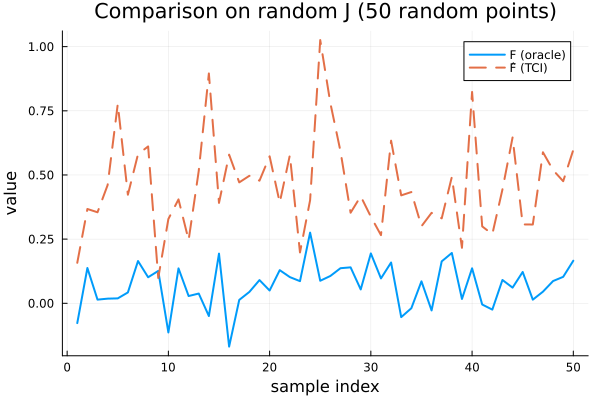

In [34]:
#Test pre-trained simple

using TensorCrossInterpolation
import TensorCrossInterpolation as TCI
"""N be 2^k"""

N= 16
L = Int(round(log2(N)))

#------Target function-----------------
n_params = L*17 #(15 for SU4 and 2 for controlled)
random_qcnn_params = 2π .* rand(n_params)
#fq = x -> fq_ansatz2(x, N, random_qcnn_params)
fq = x->fq_ansatz2_mps(x, N,random_qcnn_params; χmax = 32 )
#trained_qcnn = qcnn # Obtained from training above


#-----------------------------

ωss = [[1] for _ in 1:N] # Should be known from the circuit, Vecotr{<:Reals}
phys_dims = [2*length(ωss[i]) + 1 for i in 1:N]

## Query points
gammas = FunctionTCI.gamma_vals(ωss)
domain_range = 1 .+ (2*π ./ gammas )

α = 2   #Integer
M_sample = α .* phys_dims
a_vec_list = [domain_range[k] .* rand(M_sample[k]) for k in 1:N]


#--------- For TCI___________________

# Hyperparameters
maxbonddim = 32
tolerance = 1e-8
dims = M_sample # Relabeling for TCI notation

#println("\n=== Running for shots = $shots ===")

#f_idx(id::Vector{Int}) = fq([ a_vec_list[p][id[p]] for p in 1:N])
# --- guard f_idx for NaN/Inf ---
bad_count = Ref(0)

f_idx(id::Vector{Int}) = fq([a_vec_list[p][id[p]] for p in 1:N])


println("bad_count = ", bad_count[])

# ---------- how to use with your tci result ----------
# 1) Extract TT(F) cores from the TCI object
tt        = TCI.TensorTrain(tci)
cores_F   = TCI.sitetensors(tt)            # Vector of (rL,3,rR)


# 3) Relative 2-norm (Frobenius) error on the grid
relF = relerr_grid_2norm(f_idx, dims, cores_F; nsamples=2000, seed=123)
println("\n=== RETURNS ===")
println("tci :: ", typeof(tci))
println("ranks :: ", ranks)
println("errors:: ", errors)
println("last error = ", isempty(errors) ? NaN : last(errors),
        "  (below tol? ", (isempty(errors) ? false : last(errors) < tolerance), ")")

println("\n=== BASIC PROPERTIES OF tci ===")
println("length(tci)    = ", length(tci))          # number of modes
println("rank(tci)      = ", TCI.rank(tci))        # max bond dimension
println("linkdims(tci)  = ", TCI.linkdims(tci))    # bond dims per link

# The errors are normalized by the max |f| seen unless you pass normalizeerror=false.
# You can inspect the normalization and the pivot-error curve stored on tci:
println("maxsamplevalue = ", tci.maxsamplevalue)
println("pivoterrors (stored on object) length = ", length(tci.pivoterrors))


println("Relative 2-norm (Frobenius) error on grid = ", relF)
#println("Number of shots =", shots)

println("site (physical) dims = ", TCI.sitedims(tt))
cores_F = TCI.sitetensors(tt)
cores_C = ttF_to_ttC(cores_F, ωss ; auxs = a_vec_list)
bond_dims = [size(core, 3) for core in cores_C]
println("Bond dimensions (size(core,3)) in cores_C: ", bond_dims)
maximum_bond_dim = maximum(bond_dims)
println("Maximum bond dimension in cores_C: ", maximum_bond_dim)
phis = [x -> x[i] for i in 1:N]
t = make_basis_vectors(ωss, phis)

p, y_true, y_hat, xs, rel_error = compare_and_plot(fq, cores_C, t, N; M=50, seed=1223)


println("Relative error for function = $(rel_error)")
display(p)



In [41]:
# --- quick sanity check on f_idx distribution ---

N= 32
L = Int(round(log2(N)))

#------Target function-----------------
n_params = L*17 #(15 for SU4 and 2 for controlled)
random_qcnn_params = 2π .* rand(n_params)
#fq = x -> fq_ansatz2(x, N, random_qcnn_params)
fq = x->fq_ansatz2_mps(x, N,random_qcnn_params; χmax = 64 )
bad_count = Ref(0)



function sanity_check_fidx(f_idx_raw, dims; nsamples=200, seed=0)
    rng = MersenneTwister(seed)
    vals = Float64[]
    for _ in 1:nsamples
        I = [rand(rng, 1:d) for d in dims]
        push!(vals, f_idx_raw(I))
    end
    println("f_idx: finite = ", count(isfinite, vals), "/", length(vals))
    println("min/max = ", minimum(vals), " / ", maximum(vals))
    println("std = ", std(vals))
end

f_idx_raw(id::Vector{Int}) = fq([a_vec_list[p][id[p]] for p in 1:N])
sanity_check_fidx(f_idx_raw, dims; nsamples=200, seed=123)


f_idx: finite = 200/200
min/max = -0.2372422629703601 / 0.3031579604404298
std = 0.10459297764090006


In [42]:
# Run QCNN+TCI over N=6:12, 5 random conv_params, collect and save metrics.
using TensorCrossInterpolation
import TensorCrossInterpolation as TCI
using Statistics
using Serialization
using Printf
using Plots
using LinearAlgebra
import Dates

# Create directories if missing
qcdata_dir = "Datas/QCNN"
qcfigs_dir = "Figs/Numerics/QCNN"
isdir(qcdata_dir) || mkpath(qcdata_dir)
isdir(qcfigs_dir) || mkpath(qcfigs_dir)

Ns = [4,8,16,32]                # system sizes
num_trials = 5           # number of random conv_params
maxbonddim = 64
tolerance = 1e-8

results = Dict()

# Loop over system sizes
for N in Ns
    println("\n========== Running for N = $N ==========")

    L = Int(round(log2(N)))


    ωss = [[1] for _ in 1:N]
    phys_dims = [2*length(ωss[i]) + 1 for i in 1:N]
    gammas = FunctionTCI.gamma_vals(ωss)
    domain_range = 1 .+ (2*π ./ gammas)
    α = 2
    M_sample = α .* phys_dims
    dims = M_sample

    # Save per-trial results
    trial_rank = Float64[]
    trial_n_evals = Int[]
    trial_rel_err = Float64[]
    trial_rel_F = Float64[]
    trial_test_xs =[]
    trial_parameters = []
    trial_cores_C = []
    trial_rank_C = Float64[]  # <-- new: to store rank_C per trial

    for trial = 1:num_trials
        println("-- trial $trial")

        n_params = L*17 #(15 for SU4 and 2 for controlled)
        random_qcnn_params = 2π .* rand(n_params)
        #fq = x -> fq_ansatz2(x, N, random_qcnn_params)
        fq = x->fq_ansatz2_mps(x, N,random_qcnn_params; χmax = 64 )

        # Sample points for this trial (different per conv_params)
        a_vec_list = [domain_range[k] .* rand(M_sample[k]) for k in 1:N]
        f_idx(id::Vector{Int}) = fq([a_vec_list[p][id[p]] for p in 1:N])
        ctr = CounterWithLog(0, Dict{Tuple{Vararg{Int}},Float64}(), Vector{Vector{Int}}(), false)  # true = verbose logging
        f_cached = counted_unique_with_log(f_idx, ctr)

        # Run TCI
        t_start = time()
        tci, ranks, errors = TensorCrossInterpolation.crossinterpolate2(
            Float64, f_cached, dims; pivotsearch=:full, tolerance=tolerance, maxbonddim=maxbonddim
        )
        t_elapsed = time() - t_start
        println("time elasped for tci, $t_elapsed")

        # Extract rank, n_evals (from object, if possible), and rel_error
        cur_rank = TCI.rank(tci)
        ctr_n = ctr.n
        tt = TCI.TensorTrain(tci)
        cores_F = TCI.sitetensors(tt)


        rel_F = relerr_grid_2norm(f_idx, dims, cores_F; nsamples=1000, seed=trial*999+N*111)
        # Compute also relative error with compare_and_plot (slow, smaller M)
        
        cores_C = ttF_to_ttC(cores_F, ωss ; auxs = a_vec_list)
        bond_dims = [size(core, 3) for core in cores_C]
        println("Bond dimensions (size(core,3)) in cores_C: ", bond_dims)
        rank_C = maximum(bond_dims)
        phis = [x -> x[i] for i in 1:N]
        t = make_basis_vectors(ωss, phis)
        #_, _, _, _, rel_error = compare_and_plot(fq, cores_C, t, N; M=50, seed=trial*1234)
        t_start_compare = time()
        trial_xs, rel_error = compare_only(fq, cores_C, t, N; M=50, seed=trial*1234)
        println("    compare_only elapsed: ", round(time()-t_start_compare; sigdigits=4), "s")
        

        push!(trial_rank, cur_rank)
        push!(trial_n_evals, ctr_n)
        push!(trial_rel_F, rel_F)
        push!(trial_rel_err, rel_error)
        push!(trial_test_xs, trial_xs)
        push!(trial_parameters, random_qcnn_params)
        push!(trial_cores_C, cores_C)
        push!(trial_rank_C, rank_C)  # <-- new: save rank_C
        println("  rank: $cur_rank, evals: $ctr_n, relF: $(round(rel_F; sigdigits=4)), rel_err: $(round(rel_error; sigdigits=4)), rank_C: $rank_C")
    end

    results[N] = Dict(
        :rank => copy(trial_rank),
        :n_evals => copy(trial_n_evals),
        :rel_F => copy(trial_rel_F),
        :rel_error => copy(trial_rel_err),
        :xs => copy(trial_test_xs),
        :parameters => copy(trial_parameters),
        :cores_C => copy(trial_cores_C),
        :rank_C => copy(trial_rank_C),   # <-- new: save per-trial rank_C
    )

    # Save intermediate data, with '64' added at end of the filename
    serialize(joinpath(qcdata_dir, "QCNN_N$(N)_64.jls"), results[N])
end

# Save all results together with '64' added at the end of the filename
serialize(joinpath(qcdata_dir, "QCNN_all_N_$(Dates.format(Dates.now(), "yyyymmdd_HHMM"))_64.jls"), results)

# Compute averages and plot
Ns_vec = collect(Ns)
rank_mat = [mean(results[N][:rank]) for N in Ns_vec]
rank_C_mat = [mean(results[N][:rank_C]) for N in Ns_vec]  # <-- new: avg. rank_C
n_evals_mat = [mean(results[N][:n_evals]) for N in Ns_vec]
rel_F_mat = [mean(skipmissing(results[N][:rel_F])) for N in Ns_vec]
rel_err_mat = [mean(skipmissing(results[N][:rel_error])) for N in Ns_vec]

# Plot: Max Rank (TCI internal)
plt1 = Plots.plot(Ns_vec, rank_mat, marker=:circle, linewidth=3, xlabel="N", ylabel="Avg. TCI Rank", title="Avg. TCI Max Rank vs N", legend=false)
display(plt1)
savefig(plt1, joinpath(qcfigs_dir, "avg_TCIRank_vs_N_64.pdf"))

# Plot: Max Rank (Physical rank_C)
plt1b = Plots.plot(Ns_vec, rank_C_mat, marker=:utriangle, linewidth=3, xlabel="N", ylabel="Avg. Physical Max Rank (rank_C)", title="Avg. Physical Max Rank (rank_C) vs N", legend=false)
display(plt1b)
savefig(plt1b, joinpath(qcfigs_dir, "avg_PhysicalRankC_vs_N_64.pdf"))

# Plot: Num Function Evaluations
plt2 = Plots.plot(Ns_vec, n_evals_mat, marker=:diamond, linewidth=3, xlabel="N", ylabel="Avg. # Function evals", title="Avg. # Function evals vs N", legend=false)
display(plt2)
savefig(plt2, joinpath(qcfigs_dir, "avg_func_evals_vs_N_64.pdf"))

# Plot: Relative Error (grid)
plt3 = Plots.plot(Ns_vec, rel_F_mat, marker=:star, linewidth=3, xlabel="N", ylabel="Avg. rel-2-norm Error", title="Avg. rel-2-norm Error vs N", legend=false)
display(plt3)
savefig(plt3, joinpath(qcfigs_dir, "avg_relF_vs_N_64.pdf"))

# Plot: Relative Error (sampled test points)
plt4 = Plots.plot(Ns_vec, rel_err_mat, marker=:x, linewidth=3, xlabel="N", ylabel="Avg. Test rel. Error", title="Avg. Test rel. Error vs N", legend=false)
display(plt4)
savefig(plt4, joinpath(qcfigs_dir, "avg_test_relerr_vs_N_64.pdf"))

println("\nSaved data in $qcdata_dir and figures in $qcfigs_dir with _64 added to filenames.")



========== Running for N = 4 ==========
-- trial 1
time elasped for tci, 0.7065930366516113
Bond dimensions (size(core,3)) in cores_C: [3, 4, 3, 1]
RMSE = 1.559683172571584e-15, rel_RMSE = 3.598117932352511e-15, max |error| = 3.524958103184872e-15 over M=50 random points
    compare_only elapsed: 0.3157s
  rank: 4, evals: 760, relF: 4.437e-15, rel_err: 3.598e-15, rank_C: 4
-- trial 2
time elasped for tci, 0.3404541015625
Bond dimensions (size(core,3)) in cores_C: [3, 4, 3, 1]
RMSE = 2.665966919911548e-15, rel_RMSE = 6.717634260274016e-15, max |error| = 5.551115123125783e-15 over M=50 random points
    compare_only elapsed: 0.006876s
  rank: 4, evals: 725, relF: 5.712e-15, rel_err: 6.718e-15, rank_C: 4
-- trial 3
time elasped for tci, 0.32105493545532227
Bond dimensions (size(core,3)) in cores_C: [3, 4, 3, 1]
RMSE = 1.7498325527807055e-15, rel_RMSE = 9.124026311228813e-15, max |error| = 3.7192471324942744e-15 over M=50 random points
    compare_only elapsed: 0.007669s
  rank: 4, evals:

LAPACKException: LAPACKException(1)

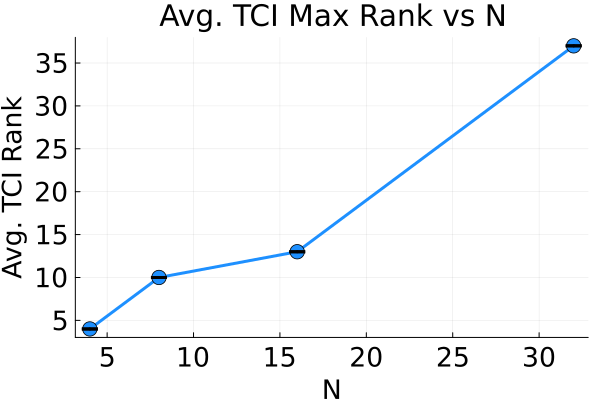

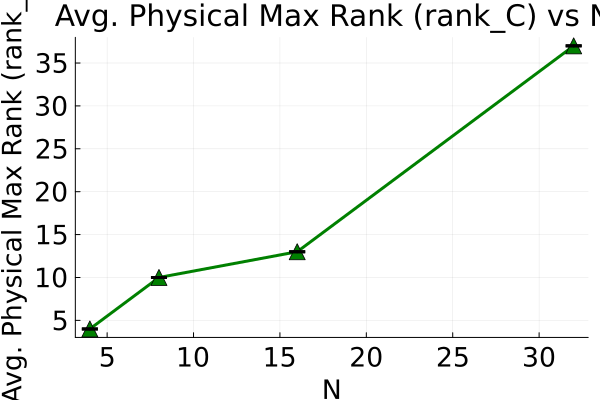

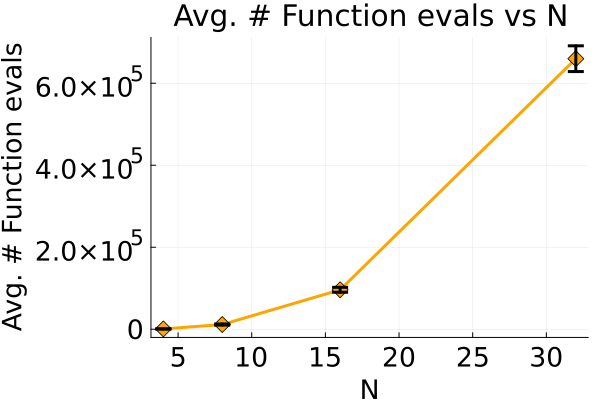

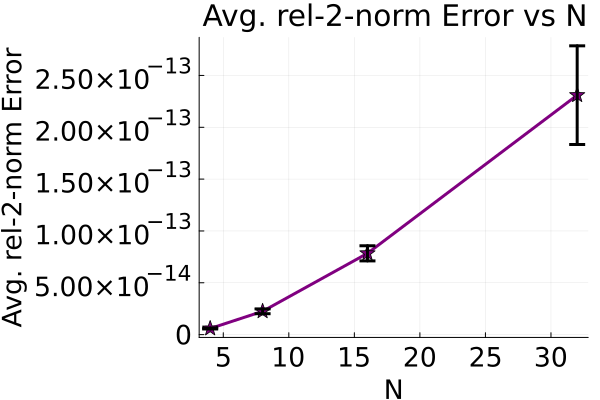

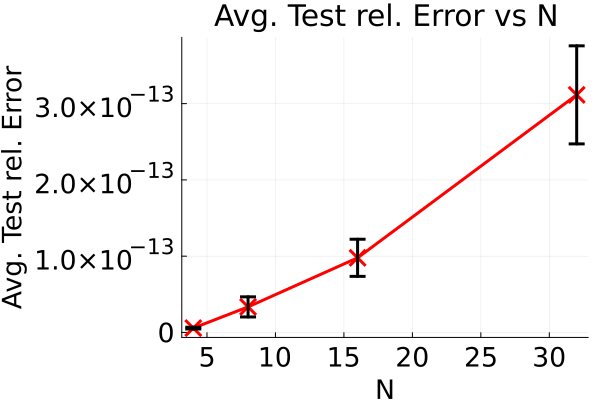


Saved data in Datas/QCNN and figures in Figs/Numerics/QCNN.


In [38]:

using Statistics

# Compute averages and standard errors
Ns_vec = collect(Ns)

function mean_and_stderr(arr)
    m = mean(arr)
    N = length(arr)
    std = Statistics.std(arr)
    stderr = isnan(std) ? 0.0 : std / sqrt(N)
    return m, stderr
end

# For arrays with missing values, skipmissing for both mean and std err
function mean_and_stderr_skipmissing(arr)
    arr_nomiss = collect(skipmissing(arr))
    return mean_and_stderr(arr_nomiss)
end

rank_stats = [mean_and_stderr(results[N][:rank]) for N in Ns_vec]
rank_m, rank_se = first.(rank_stats), last.(rank_stats)

rank_C_stats = [mean_and_stderr(results[N][:rank_C]) for N in Ns_vec]
rank_C_m, rank_C_se = first.(rank_C_stats), last.(rank_C_stats)

n_evals_stats = [mean_and_stderr(results[N][:n_evals]) for N in Ns_vec]
n_evals_m, n_evals_se = first.(n_evals_stats), last.(n_evals_stats)

rel_F_stats = [mean_and_stderr_skipmissing(results[N][:rel_F]) for N in Ns_vec]
rel_F_m, rel_F_se = first.(rel_F_stats), last.(rel_F_stats)

rel_err_stats = [mean_and_stderr_skipmissing(results[N][:rel_error]) for N in Ns_vec]
rel_err_m, rel_err_se = first.(rel_err_stats), last.(rel_err_stats)

# Set font sizes for axis/labels/titles/ticks
fs_title = 20
fs_label = 18
fs_ticks = 18
ms = 8 # marker size, a little bit larger than default

# Plot: Max Rank (TCI internal)
plt1 = Plots.plot(Ns_vec, rank_m, yerror=rank_se, marker=:circle, markersize=ms, linewidth=3, xlabel="N", ylabel="Avg. TCI Rank",
    title="Avg. TCI Max Rank vs N", legend=false, color=:dodgerblue,
    titlefontsize=fs_title, guidefontsize=fs_label, tickfontsize=fs_ticks)
display(plt1)
savefig(plt1, joinpath(qcfigs_dir, "avg_TCIRank_vs_N.svg"))

# Plot: Max Rank (Physical rank_C)
plt1b = Plots.plot(Ns_vec, rank_C_m, yerror=rank_C_se, marker=:utriangle, markersize=ms, linewidth=3, xlabel="N", ylabel="Avg. Physical Max Rank (rank_C)",
    title="Avg. Physical Max Rank (rank_C) vs N", legend=false, color=:green,
    titlefontsize=fs_title, guidefontsize=fs_label, tickfontsize=fs_ticks)
display(plt1b)
savefig(plt1b, joinpath(qcfigs_dir, "avg_PhysicalRankC_vs_N.svg"))

# Plot: Num Function Evaluations
plt2 = Plots.plot(Ns_vec, n_evals_m, yerror=n_evals_se, marker=:diamond, markersize=ms, linewidth=3, xlabel="N", ylabel="Avg. # Function evals",
    title="Avg. # Function evals vs N", legend=false, color=:orange,
    titlefontsize=fs_title, guidefontsize=fs_label, tickfontsize=fs_ticks)
display(plt2)
savefig(plt2, joinpath(qcfigs_dir, "avg_func_evals_vs_N.svg"))

# Plot: Relative Error (grid)
plt3 = Plots.plot(Ns_vec, rel_F_m, yerror=rel_F_se, marker=:star, markersize=ms, linewidth=3, xlabel="N", ylabel="Avg. rel-2-norm Error",
    title="Avg. rel-2-norm Error vs N", legend=false, color=:purple,
    titlefontsize=fs_title, guidefontsize=fs_label, tickfontsize=fs_ticks)
display(plt3)
savefig(plt3, joinpath(qcfigs_dir, "avg_relF_vs_N.svg"))

# Plot: Relative Error (sampled test points)
plt4 = Plots.plot(Ns_vec, rel_err_m, yerror=rel_err_se, marker=:x, markersize=ms, linewidth=3, xlabel="N", ylabel="Avg. Test rel. Error",
    title="Avg. Test rel. Error vs N", legend=false, color=:red,
    titlefontsize=fs_title, guidefontsize=fs_label, tickfontsize=fs_ticks)
display(plt4)
savefig(plt4, joinpath(qcfigs_dir, "avg_test_relerr_vs_N.svg"))

println("\nSaved data in $qcdata_dir and figures in $qcfigs_dir.")


In [17]:
L = Int(log2(64))
n_params = L*17 #(15 for SU4 and 2 for controlled)
random_qcnn_params = 2π .* rand(n_params)
fq = x->fq_ansatz2_mps(x, 64,random_qcnn_params; χmax = 32 )
a = randn(64)
fq(a)

-0.04948319590473799


=== RETURNS ===
tci :: TensorCrossInterpolation.TensorCI2{Float64}
ranks :: [15, 13, 13, 13]
errors:: [4.2296241390042464e-15, 5.4600077386765365e-15, 5.8712353966152104e-15, 5.8712353966152104e-15]
last error = 5.8712353966152104e-15  (below tol? true)

=== BASIC PROPERTIES OF tci ===
length(tci)    = 16
rank(tci)      = 13
linkdims(tci)  = [3, 4, 10, 4, 12, 13, 10, 4, 10, 13, 12, 4, 10, 4, 3]
maxsamplevalue = 0.700308168736651
pivoterrors (stored on object) length = 14
Relative 2-norm (Frobenius) error on grid = 1.0081194048003586e-14
site (physical) dims = [[6], [6], [6], [6], [6], [6], [6], [6], [6], [6], [6], [6], [6], [6], [6], [6]]
RMSE = 1.400191507378259e-15, rel_RMSE = 7.27447530291535e-15, max |error| = 3.948230631323213e-15 over M=50 random points
Relative error for function = 7.27447530291535e-15


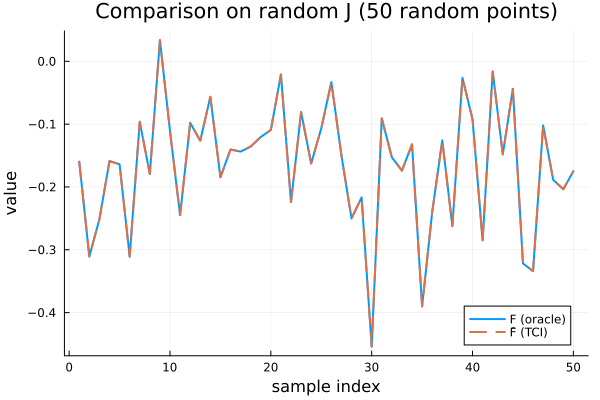

In [42]:

#Test pre-trained simple

using TensorCrossInterpolation
import TensorCrossInterpolation as TCI
"""N be 2^k"""

N= 16
L = Int(round(log2(N)))
n_params = L*17 #(15 for SU4 and 2 for controlled)

#------Target function-----------------
p_random = 2π .* rand(n_params)
fq = x -> predict_scalar(x, p_random, N)
#-----------------------------

ωss = [[1] for _ in 1:N] # Should be known from the circuit, Vecotr{<:Reals}
phys_dims = [2*length(ωss[i]) + 1 for i in 1:N]

## Query points
gammas = FunctionTCI.gamma_vals(ωss)
domain_range = 1 .+ (2*π ./ gammas )

α = 2   #Integer
M_sample = α .* phys_dims
a_vec_list = [domain_range[k] .* rand(M_sample[k]) for k in 1:N]


#--------- For TCI___________________

# Hyperparameters
maxbonddim = 16
tolerance = 1e-8
dims = M_sample # Relabeling for TCI notation

#println("\n=== Running for shots = $shots ===")

f_idx(id::Vector{Int}) = fq([ a_vec_list[p][id[p]] for p in 1:N])

tci, ranks, errors = TensorCrossInterpolation.crossinterpolate2(
    Float64, f_idx, dims; pivotsearch = :full, tolerance=tolerance, maxbonddim = maxbonddim
)

# ---------- how to use with your tci result ----------
# 1) Extract TT(F) cores from the TCI object
tt        = TCI.TensorTrain(tci)
cores_F   = TCI.sitetensors(tt)            # Vector of (rL,3,rR)


# 3) Relative 2-norm (Frobenius) error on the grid
relF = relerr_grid_2norm(f_idx, dims, cores_F; nsamples=20_000, seed=123)
println("\n=== RETURNS ===")
println("tci :: ", typeof(tci))
println("ranks :: ", ranks)
println("errors:: ", errors)
println("last error = ", isempty(errors) ? NaN : last(errors),
        "  (below tol? ", (isempty(errors) ? false : last(errors) < tolerance), ")")

println("\n=== BASIC PROPERTIES OF tci ===")
println("length(tci)    = ", length(tci))          # number of modes
println("rank(tci)      = ", TCI.rank(tci))        # max bond dimension
println("linkdims(tci)  = ", TCI.linkdims(tci))    # bond dims per link

# The errors are normalized by the max |f| seen unless you pass normalizeerror=false.
# You can inspect the normalization and the pivot-error curve stored on tci:
println("maxsamplevalue = ", tci.maxsamplevalue)
println("pivoterrors (stored on object) length = ", length(tci.pivoterrors))


println("Relative 2-norm (Frobenius) error on grid = ", relF)
#println("Number of shots =", shots)

println("site (physical) dims = ", TCI.sitedims(tt))
cores_F = TCI.sitetensors(tt)
cores_C = ttF_to_ttC(cores_F, ωss ; auxs = a_vec_list)
phis = [x -> x[i] for i in 1:N]
t = make_basis_vectors(ωss, phis)

p, y_true, y_hat, xs, rel_error = compare_and_plot(fq, cores_C, t, N; M=50, seed=1223)


println("Relative error for function = $(rel_error)")
display(p)



##Compare between trained and untrained model

In [ ]:
using Random, LinearAlgebra, Statistics
using Yao, YaoBlocks


"""For training """
# ------------------------------
# NEW parameterization (17 per layer)
# ------------------------------
num_layers(n_total::Int) = Int(log2(n_total))
num_params_qcnn(n_total::Int) = 17 * num_layers(n_total)

# ------------------------------
# Measurement + forward pass (x -> scalar)
# ------------------------------
meas_Z(n_total::Int, out_qubit::Int) = put(n_total, out_qubit => Z)

function predict_scalar(x::AbstractVector{<:Real}, p::AbstractVector{<:Real}, n_total::Int)
    @assert ispow2(n_total) "This QCNN requires n_total = 2^k."
    @assert length(p) == num_params_qcnn(n_total) "Expected $(num_params_qcnn(n_total)) params, got $(length(p))."

    circ, out_qubit = build_qcnn_ansatz2(n_total, p)

    reg = simple_encode_state(n_total, x)
    apply!(reg, circ)

    ŷ = expect(meas_Z(n_total, out_qubit), reg)  # ⟨Z_out⟩ ∈ [-1,1]
    return float(ŷ)
end

function predict_batch(X, p::AbstractVector{<:Real}, n_total::Int)
    if X isa AbstractMatrix
        return [predict_scalar(view(X, i, :), p, n_total) for i in 1:size(X, 1)]
    else
        return [predict_scalar(x, p, n_total) for x in X]
    end
end

mse_loss(X, y::AbstractVector{<:Real}, p::AbstractVector{<:Real}, n_total::Int) =
    mean((predict_batch(X, p, n_total) .- y).^2)

# ------------------------------
# Parameter-shift gradients (unchanged logic; uses predict_scalar)
# Works for Ry/Rz and controlled-Ry with shift = π/2
# ------------------------------
function grad_f_paramshift(x::AbstractVector{<:Real}, p::Vector{Float64}, n_total::Int, i::Int; shift::Float64=pi/2)
    pplus = copy(p);  pplus[i]  += shift
    pminus = copy(p); pminus[i] -= shift
    return 0.5 * (predict_scalar(x, pplus, n_total) - predict_scalar(x, pminus, n_total))
end

function grad_mse_paramshift(X, y::AbstractVector{<:Real}, p::Vector{Float64}, n_total::Int; shift::Float64=pi/2)
    xs = (X isa AbstractMatrix) ? [Vector{Float64}(view(X, i, :)) for i in 1:size(X, 1)] : collect(X)
    ys = Vector{Float64}(y)
    B  = length(ys)
    @assert B > 0

    f = [predict_scalar(xs[b], p, n_total) for b in 1:B]
    dL_df = (2.0 / B) .* (f .- ys)

    g = zeros(Float64, length(p))
    for i in 1:length(p)
        acc = 0.0
        for b in 1:B
            acc += dL_df[b] * grad_f_paramshift(xs[b], p, n_total, i; shift=shift)
        end
        g[i] = acc
    end
    @assert all(isfinite, g)
    return g
end

# ------------------------------
# Adam + training (only init changed: npar = 17*log2(n_total))
# ------------------------------
mutable struct AdamState
    m::Vector{Float64}
    v::Vector{Float64}
    t::Int
end
adam_init(n::Int) = AdamState(zeros(n), zeros(n), 0)

function adam_step!(p::Vector{Float64}, g::Vector{Float64}, st::AdamState;
                    lr::Float64=0.02, β1::Float64=0.9, β2::Float64=0.999, ϵ::Float64=1e-8)
    st.t += 1
    st.m .= β1 .* st.m .+ (1-β1) .* g
    st.v .= β2 .* st.v .+ (1-β2) .* (g .^ 2)
    mhat = st.m ./ (1 - β1^st.t)
    vhat = st.v ./ (1 - β2^st.t)
    p .-= lr .* mhat ./ (sqrt.(vhat) .+ ϵ)
    return p
end

function each_minibatch(X::AbstractMatrix{<:Real}, y::AbstractVector{<:Real}, batchsize::Int;
                        shuffle::Bool=true, rng::AbstractRNG=Random.default_rng())
    n = size(X, 1)
    @assert length(y) == n
    idx = collect(1:n)
    shuffle && Random.shuffle!(rng, idx)
    batches = [idx[s:min(s+batchsize-1, n)] for s in 1:batchsize:n]
    return ((view(X, b, :), view(y, b)) for b in batches)
end

function train_qcnn!(X_train::AbstractMatrix{<:Real}, y_train::AbstractVector{<:Real};
                     n_total::Int, epochs::Int=30, batchsize::Int=8, lr::Float64=0.02,
                     seed::Int=1, shift::Float64=pi/2, verbose::Bool=true)

    @assert ispow2(n_total) "This QCNN requires n_total = 2^k."
    @assert size(X_train, 2) <= n_total "simple_encode_state uses first min(n_total, length(x)) entries."
    @assert length(y_train) == size(X_train, 1)

    rng = MersenneTwister(seed)
    npar = num_params_qcnn(n_total)
    p = 0.01 .* randn(rng, npar)
    p_init = deepcopy(p)
    st = adam_init(npar)

    verbose && println("Initial train loss = ", mse_loss(X_train, y_train, p, n_total))

    for ep in 1:epochs
        for (Xb, yb) in each_minibatch(X_train, y_train, batchsize; shuffle=true, rng=rng)
            g = grad_mse_paramshift(Xb, yb, p, n_total; shift=shift)
            adam_step!(p, g, st; lr=lr)
        end
        verbose && println("Epoch $(ep): train loss = ", mse_loss(X_train, y_train, p, n_total))
    end

    @assert all(isfinite, p)
    return p, p_init
end

# ------------------------------
# Verification (run once)
# ------------------------------
function self_check(; n_total::Int=4, n_samples::Int=5, seed::Int=123)
    @assert ispow2(n_total)
    rng = MersenneTwister(seed)
    X = randn(rng, n_samples, n_total)
    y = tanh.(0.3 .* sum(X; dims=2))[:]

    p = 0.01 .* randn(rng, num_params_qcnn(n_total))

    ŷ = predict_batch(X, p, n_total)
    @assert all(isfinite, ŷ)

    g = grad_mse_paramshift(X, y, copy(p), n_total)
    @assert length(g) == length(p)
    @assert all(isfinite, g)

    st = adam_init(length(p))
    adam_step!(p, g, st; lr=0.01)
    @assert all(isfinite, p)

    println("Self-check passed (forward/grad/step are finite, parameter count = $(length(p))).")
    return true
end


self_check (generic function with 1 method)

In [61]:
using MultivariateStats, Statistics

"""For dataset"""

# PCA preprocessing for Fashion-MNIST to n_qubits features
function load_binary_fashion(; class_pos=0, class_neg=1, n_train=4000, n_test=500, n_qubits=8)
    ENV["DATADEPS_ALWAYS_ACCEPT"] = "true"

    train_ds = MLDatasets.FashionMNIST(split=:train)
    test_ds  = MLDatasets.FashionMNIST(split=:test)

    train_x, train_y = train_ds.features, train_ds.targets
    test_x,  test_y  = test_ds.features,  test_ds.targets

    train_idx = findall(y -> y == class_pos || y == class_neg, train_y)
    test_idx  = findall(y -> y == class_pos || y == class_neg, test_y)
    train_idx = train_idx[1:min(length(train_idx), n_train)]
    test_idx  = test_idx[1:min(length(test_idx),  n_test)]

    # fit PCA on selected training subset (columns are samples)
    Xtrain = Float32.(reshape(train_x[:, :, train_idx], :, length(train_idx))) ./ 255f0
    pca = fit(PCA, Xtrain; maxoutdim=n_qubits, mean=nothing)
    proj_train = transform(pca, Xtrain)
    minv = minimum(proj_train); maxv = maximum(proj_train)
    denom = maxv - minv + eps(Float32)

    encode = function(img)
        x = Float32.(vec(img)) ./ 255f0
        z = transform(pca, x)[1:n_qubits]
        z = clamp.((z .- minv) ./ denom, 0f0, 1f0)
        return π .* z
    end

    xs_train = hcat([encode(train_x[:, :, i]) for i in train_idx]...)'
    xs_test  = hcat([encode(test_x[:, :, i])  for i in test_idx]...)'

    ys_train = Float32.([train_y[i] == class_pos ? 1.0f0 : -1.0f0 for i in train_idx])
    ys_test  = Float32.([test_y[i] == class_pos ? 1.0f0 : -1.0f0 for i in test_idx])

    return (xs_train, ys_train), (xs_test, ys_test)
end

# --- 2. Example regression dataset, e.g. BostonHousing with <=16 features ---
# This requires installing MLJ or RDatasets:
using RDatasets

function load_boston_regression(; n_train=1000, n_test=100, n_qubits=13)
    data = dataset("MASS", "Boston")
    X = Matrix(data[:, Not(:MedV)])
    y_raw = Float32.(data.MedV)
    n_samples, n_features = size(X)
    if n_features > n_qubits
        # Reduce features to n_qubits via PCA
        X = Float32.(X')
        pca = fit(PCA, X; maxoutdim=n_qubits, mean=nothing)
        Xp = transform(pca, X)'
    else
        Xp = Float32.(X)
    end
    # Scale Xp to [0,π]
    minv = minimum(Xp); maxv = maximum(Xp)
    Xp = clamp.((Xp .- minv) ./ (maxv - minv + eps()), 0f0, 1f0)
    Xp = π .* Xp

    # Normalize y to [-1, 1]
    y_min = minimum(y_raw)
    y_max = maximum(y_raw)
    y = 2f0 .* ((y_raw .- y_min) ./ (y_max - y_min + eps(Float32))) .- 1f0

    # Shuffle and split
    idx = shuffle(1:n_samples)
    train_idx = idx[1:min(end, n_train)]
    test_idx  = idx[(n_train+1):min(end, n_train+n_test)]
    xs_train = Xp[train_idx, :]
    xs_test  = Xp[test_idx, :]
    ys_train = y[train_idx]
    ys_test  = y[test_idx]
    return (xs_train, ys_train), (xs_test, ys_test)
end

load_boston_regression (generic function with 1 method)

In [62]:
# Example: build your QCNN once (using the builder you already implemented)
N = 4
L = Int(round(log2(N)))

epochs = 10
batchsize = 16
lr = 0.03

# xs_train => Matrix (n_samples x n_features), with n_features <= n_total
# ys_train => Vector length n_samples, ideally scaled to roughly [-1,1]

(xs_train, ys_train), (xs_test, ys_test) = load_binary_fashion(n_qubits = N)
(xs_train, ys_train), (xs_test, ys_test) = load_boston_regression(n_qubits = N)

p_star, p_init = train_qcnn!(xs_train, ys_train; n_total=N, epochs=epochs, batchsize=batchsize, lr=lr)

fq = x -> fq_ansatz2(x, N, p_star)

# Predict
y_pred = predict_batch(xs_test, p_star, N)
y_pred = [abs(y - 1) < abs(y + 1) ? 1.0 : -1.0 for y in y_pred]

rmse = sqrt(mean(y_pred.-ys_test).^2)
diff_count = length(ys_test) - sum(abs.(y_pred.+ys_test)./2)
println("Number of differences between y_pred and ys_test: $diff_count")
println("Root mean square error =$(rmse)")


Initial train loss = 0.20819078648299363
Epoch 1: train loss = 0.1352967843712192
Epoch 2: train loss = 0.12841225077749663
Epoch 3: train loss = 0.12626892778715096
Epoch 4: train loss = 0.1267365364726937
Epoch 5: train loss = 0.13007297565128775
Epoch 6: train loss = 0.12008683517235051
Epoch 7: train loss = 0.12763013892385675
Epoch 8: train loss = 0.14264132960551043
Epoch 9: train loss = 0.1358372495581459
Epoch 10: train loss = 0.12817174137583262
Number of differences between y_pred and ys_test: 0.0
Root mean square error =NaN



========== Training + TCI for N = 4 ==========
Initial train loss = 1.066222759722692
Epoch 1: train loss = 0.3027786834941818
Epoch 2: train loss = 0.2948039320710795
Epoch 3: train loss = 0.29601639105730637
Epoch 4: train loss = 0.29319594460571025
Epoch 5: train loss = 0.29405269820823765

========== Training + TCI for N = 8 ==========
Initial train loss = 1.077722022846068
Epoch 1: train loss = 0.3155781703376856
Epoch 2: train loss = 0.30587206511544457
Epoch 3: train loss = 0.2958384434299269
Epoch 4: train loss = 0.2936827757521112
Epoch 5: train loss = 0.29535892071892744

========== Training + TCI for N = 16 ==========
Initial train loss = 1.1005115551839815
Epoch 1: train loss = 0.30999178060838584
Epoch 2: train loss = 0.3078111867363858
Epoch 3: train loss = 0.28805300868128997
Epoch 4: train loss = 0.3097040461750144
Epoch 5: train loss = 0.29801302111350425


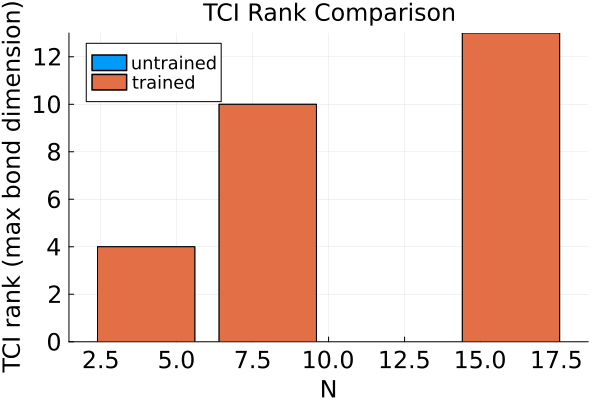

"./Figs/TCI_rank_untrained_vs_trained.png"

In [ ]:
using TensorCrossInterpolation
import TensorCrossInterpolation as TCI
using Serialization
using Statistics
using Printf
using Plots
import Dates

# ------------------------------
# Config
# ------------------------------
Ns = [4, 8, 16]
epochs = 5
batchsize = 16
lr = 0.03
maxbonddim = 16
tolerance = 1e-8

# Load untrained results (already saved)
untrained_path = "Datas/QCNN/QCNN_all_N_20260116_1324.jls"
untrained = deserialize(untrained_path)

# Container for trained results
trained_results = Dict{Int, Dict}()

# ------------------------------
# Train + TCI for each N
# ------------------------------
for N in Ns
    println("\n========== Training + TCI for N = $N ==========")

    # Dataset (same loader as in notebook)
    (xs_train, ys_train), (xs_test, ys_test) = load_binary_fashion(n_qubits = N)

    # Train QCNN (ansatz2)
    p_star, p_init = train_qcnn!(xs_train, ys_train; n_total=N, epochs=epochs, batchsize=batchsize, lr=lr)

    # Simple diff_count on test set (threshold at 0.5)
    y_pred = predict_batch(xs_test, p_star, N)
    diff_count = count((y_pred .> 0.5) .!= (ys_test .> 0.5))

    # ----- TCI setup (same as in notebook) -----
    ωss = [[1] for _ in 1:N]
    phys_dims = [2*length(ωss[i]) + 1 for i in 1:N]
    gammas = FunctionTCI.gamma_vals(ωss)
    domain_range = 1 .+ (2*π ./ gammas)
    α = 2
    M_sample = α .* phys_dims
    dims = M_sample
    a_vec_list = [domain_range[k] .* rand(M_sample[k]) for k in 1:N]

    fq = x -> predict_scalar(x, p_star, N)
    f_idx(id::Vector{Int}) = fq([a_vec_list[p][id[p]] for p in 1:N])

    tci, ranks, errors = TensorCrossInterpolation.crossinterpolate2(
        Float64, f_idx, dims; pivotsearch=:full, tolerance=tolerance, maxbonddim=maxbonddim
    )

    trained_results[N] = Dict(
        :p_init => p_init,
        :p_star => p_star,
        :diff_count => diff_count,
        :rank => TCI.rank(tci)
    )

    # Save per-N trained result
    serialize(joinpath("Datas/QCNN", "QCNN_trained_N$(N)_$(Dates.format(Dates.now(), "yyyymmdd_HHMM")).jls"),
              trained_results[N])
end

# Save all trained results together
serialize(joinpath("Datas/QCNN", "QCNN_trained_all_N_$(Dates.format(Dates.now(), "yyyymmdd_HHMM")).jls"),
          trained_results)

# ------------------------------
# Bar plot: untrained vs trained rank
# ------------------------------
untrained_ranks = [mean(untrained[N][:rank]) for N in Ns]  # untrained has multiple trials
trained_ranks   = [trained_results[N][:rank] for N in Ns]

plt = bar(
    Ns,
    [untrained_ranks trained_ranks],
    xlabel = "N",
    ylabel = "TCI rank (max bond dimension)",
    label = ["untrained" "trained"],
    title = "TCI Rank Comparison",
    legend = :topleft,
    xguidefont = font(16),
    yguidefont = font(16),
    legendfont = font(12),
    titlefont = font(16),
    tickfont = font(16)
)
display(plt)
savefig(plt, "Figs/TCI_rank_untrained_vs_trained.svg")

In [63]:
untrained_path = "Datas/QCNN/QCNN_all_N_20260116_1213.jls"
untrained = deserialize(untrained_path)
untrained_ranks = [mean(untrained[N][:rank]) for N in Ns]  # untrained has multiple trials
trained_ranks   = [trained_results[N][:rank] for N in Ns]

plt = bar(
    Ns,
    [untrained_ranks trained_ranks],
    xlabel = "N",
    ylabel = "TCI rank (max bond dimension)",
    label = ["untrained" "trained"],
    title = "TCI Rank Comparison",
    legend = :topleft,
    xguidefont = font(16),
    yguidefont = font(16),
    legendfont = font(12),
    titlefont = font(16),
    tickfont = font(16)
)
display(plt)
savefig(plt, "Figs/TCI_rank_untrained_vs_trained.svg")

KeyError: KeyError: key 16 not found

In [65]:
N16 = deserialize("Datas/QCNN/QCNN_N16.jls")

Dict{Symbol, Vector} with 4 entries:
  :rank      => [13.0, 13.0, 13.0, 13.0, 13.0]
  :rel_F     => [1.56755e-14, 6.27024e-15, 9.65685e-15, 7.9562e-15, 7.8793e-15]
  :n_evals   => [89860, 72288, 79014, 116977, 108719]
  :rel_error => [1.20915e-14, 1.40206e-14, 7.81103e-15, 9.56919e-15, 1.28523e-1…

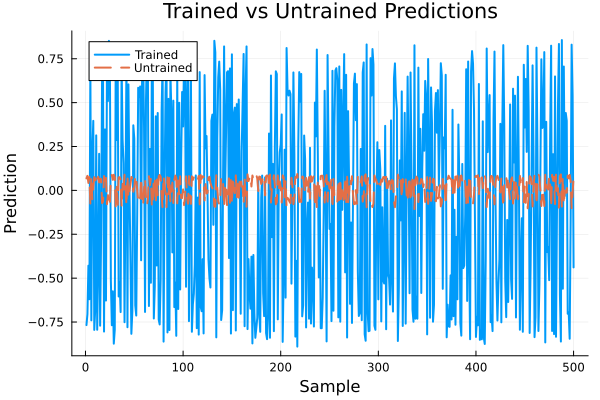